In [38]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split

## Homework 4

**Note**

This homework uses the pinned 2026 lead-scoring release in the course repository. The plan and report are available in cohorts/2026/data/.

In this homework, we will use the 2026 lead-scoring dataset. Download it from here.

In this dataset our desired target for classification task will be converted variable - has the client signed up to the platform or not.

**Data preparation**

Check if the missing values are presented in the features.
If there are missing values:
For categorical features, replace them with 'NA'
For numerical features, replace with with 0.0
Split the data into 3 parts with these exact calls:

In [39]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
df.head(5)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### **Data preparation**

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 526.0 KB


In [41]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [42]:
df.select_dtypes('str')

,lead_source,industry,employment_status,location
0,organic_search,technology,employed,europe
1,social_media,technology,employed,south_america
2,referral,retail,employed,europe
3,paid_ads,manufacturing,student,NaN
4,referral,manufacturing,student,north_america
...,...,...,...,...
4995,organic_search,education,employed,asia
4996,NaN,technology,employed,north_america
4997,organic_search,finance,employed,asia
4998,referral,technology,employed,africa


In [43]:
categorical = list(df.dtypes[(df.dtypes == 'str')].index)

In [44]:
numerical = list(df.dtypes[(df.dtypes == 'int') | (df.dtypes == 'float')].index)

In [45]:
for i in categorical:
    df[i] =  df[i].fillna("NA")

In [46]:
for i in numerical:
    df[i] =  df[i].fillna(0.0)

Split the data into 3 parts with these exact calls:

In [47]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

### **Question 1: ROC AUC feature importance**

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [48]:
#Isolate the target variables
y_train = df_train.converted.values
y_val = df_val.converted.values

In [49]:
#Remove the target variable from the training and validation dataset
del df_train['converted']
del df_val['converted']

In [50]:
from sklearn.metrics import roc_auc_score

In [51]:
numerical = [
        'lead_score',
        'number_of_courses_viewed',
        'interaction_count',
        'annual_income'
    ]

In [52]:
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(f"{col:25s}: {auc:.4f}")

lead_score               : 0.7882
number_of_courses_viewed : 0.7230
interaction_count        : 0.7649
annual_income            : 0.6082


***Answer***:  `lead_score`

### **Question 2: Training the model**

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832


In [53]:
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

In [54]:
dict_train = df_train[numerical + categorical].to_dict(orient='records')
X_train = dv.fit_transform(dict_train)
dict_val = df_val[numerical + categorical].to_dict(orient='records')
X_val = dv.transform(dict_val)

In [55]:
from sklearn.linear_model import LogisticRegression

In [56]:
#Train the model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_train)[:,1]

In [57]:
(y_pred >= 0.5).mean()

np.float64(0.801)

In [58]:
#Let us run the prediction on validation dataset
y_pred = model.predict_proba(X_val)[:,1]

In [59]:
from sklearn.metrics import roc_auc_score

In [60]:
auc = round(roc_auc_score(y_val, y_pred), 3)
auc

0.732

***Answer***: 0.732

### **Question 3: Precision and Recall**

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [61]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

precision = precision_score(y_val, y_pred >=0.5)
precision

0.6436363636363637

In [62]:
recall = recall_score(y_val, y_pred >= 0.5)
recall

0.9061433447098977

In [63]:
thresholds = np.linspace(0, 1, 101)
thresholds

precisions = []
recalls = []
for t in thresholds:
    precision = precision_score(y_val, y_pred >= t, zero_division=0)
    recall = recall_score(y_val, y_pred >=t)
    print('t=%.2f precision=%.3f recall=%.3f' % (t, precision, recall))

    precisions.append(precision)
    recalls.append(recall)



t=0.00 precision=0.586 recall=1.000
t=0.01 precision=0.586 recall=1.000
t=0.02 precision=0.586 recall=1.000
t=0.03 precision=0.586 recall=1.000
t=0.04 precision=0.586 recall=1.000
t=0.05 precision=0.586 recall=1.000
t=0.06 precision=0.586 recall=1.000
t=0.07 precision=0.586 recall=1.000
t=0.08 precision=0.586 recall=1.000
t=0.09 precision=0.586 recall=1.000
t=0.10 precision=0.586 recall=1.000
t=0.11 precision=0.586 recall=1.000
t=0.12 precision=0.586 recall=1.000
t=0.13 precision=0.586 recall=1.000
t=0.14 precision=0.586 recall=1.000
t=0.15 precision=0.586 recall=1.000
t=0.16 precision=0.586 recall=1.000
t=0.17 precision=0.586 recall=1.000
t=0.18 precision=0.586 recall=1.000
t=0.19 precision=0.586 recall=1.000
t=0.20 precision=0.586 recall=1.000
t=0.21 precision=0.586 recall=1.000
t=0.22 precision=0.586 recall=1.000
t=0.23 precision=0.586 recall=1.000
t=0.24 precision=0.586 recall=1.000
t=0.25 precision=0.586 recall=1.000
t=0.26 precision=0.587 recall=1.000
t=0.27 precision=0.588 recal

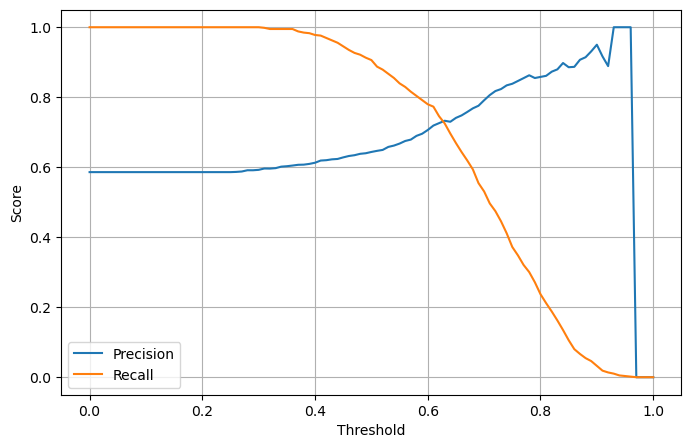

In [64]:
import matplotlib.pyplot as plt
    
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')
    
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()

  

***Answer***: 0.63

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61

In [65]:
from sklearn.metrics import f1_score
f1_scores = []
for t in thresholds:
    f1 = f1_score(y_val, y_pred >= t)
    print('t=%.2f f1=%.3f' % (t, f1))
    f1_scores.append(f1)

t=0.00 f1=0.739
t=0.01 f1=0.739
t=0.02 f1=0.739
t=0.03 f1=0.739
t=0.04 f1=0.739
t=0.05 f1=0.739
t=0.06 f1=0.739
t=0.07 f1=0.739
t=0.08 f1=0.739
t=0.09 f1=0.739
t=0.10 f1=0.739
t=0.11 f1=0.739
t=0.12 f1=0.739
t=0.13 f1=0.739
t=0.14 f1=0.739
t=0.15 f1=0.739
t=0.16 f1=0.739
t=0.17 f1=0.739
t=0.18 f1=0.739
t=0.19 f1=0.739
t=0.20 f1=0.739
t=0.21 f1=0.739
t=0.22 f1=0.739
t=0.23 f1=0.739
t=0.24 f1=0.739
t=0.25 f1=0.739
t=0.26 f1=0.739
t=0.27 f1=0.740
t=0.28 f1=0.743
t=0.29 f1=0.743
t=0.30 f1=0.744
t=0.31 f1=0.747
t=0.32 f1=0.746
t=0.33 f1=0.746
t=0.34 f1=0.750
t=0.35 f1=0.751
t=0.36 f1=0.752
t=0.37 f1=0.752
t=0.38 f1=0.751
t=0.39 f1=0.752
t=0.40 f1=0.753
t=0.41 f1=0.758
t=0.42 f1=0.756
t=0.43 f1=0.756
t=0.44 f1=0.755
t=0.45 f1=0.755
t=0.46 f1=0.754
t=0.47 f1=0.753
t=0.48 f1=0.754
t=0.49 f1=0.752
t=0.50 f1=0.753
t=0.51 f1=0.748
t=0.52 f1=0.747
t=0.53 f1=0.748
t=0.54 f1=0.746
t=0.55 f1=0.744
t=0.56 f1=0.744
t=0.57 f1=0.741
t=0.58 f1=0.742
t=0.59 f1=0.741
t=0.60 f1=0.741
t=0.61 f1=0.745
t=0.62 f

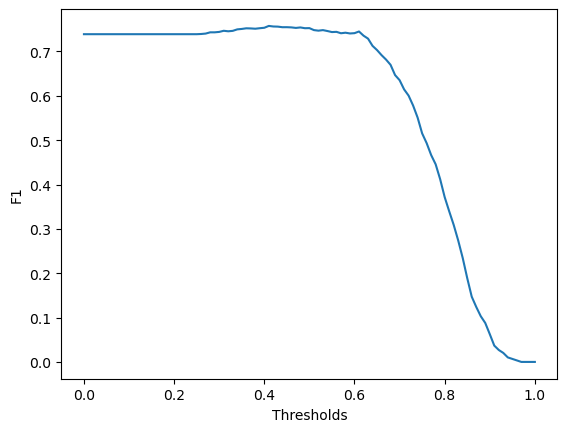

In [66]:
plt.plot(thresholds, f1_scores)
plt.xlabel('Thresholds')
plt.ylabel("F1")
plt.show()

***Answer***: 0.41

### **Question 5: 5-Fold CV**


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060


In [67]:
from sklearn.feature_extraction import DictVectorizer

In [68]:
def train (df_train, y_train, C=1.0):
    dicts = df_train[numerical + categorical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(max_iter=1000, solver='liblinear', C=C)
    model.fit(X_train, y_train)
    return dv, model

In [69]:
def predict(df, dv, model):
    dicts = df[numerical + categorical].to_dict(orient='records')
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred

In [70]:
from sklearn.model_selection import KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold.split(df_full_train)

<generator object _BaseKFold.split at 0x17aa77340>

In [71]:
scores =[]

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('Avg AUC=%.3f  AUC Std=%.3f' % (np.mean(scores), np.std(scores)))

Avg AUC=0.732  AUC Std=0.007


***Answer***: 0.007

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [72]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold.split(df_full_train)

<generator object _BaseKFold.split at 0x17a8ae240>

In [74]:

n_splits = 5

for C in [0.000001, 0.001, 1]:
    #kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s Avg AUC=%.3f AUC std=%.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 Avg AUC=0.617 AUC std=0.019
C=0.001 Avg AUC=0.749 AUC std=0.010
C=1 Avg AUC=0.732 AUC std=0.007


***Answer***: C=0.001